# 01 - Baseline: text → embedding pipeline + 5 prompt → image test runs

**Project:** text-to-image generation with CLIP + Stable Diffusion v1.5 on a curated COCO subset.

This notebook covers task 4 (baseline text→embedding pipeline) and produces the "5 sample prompt→image runs" deliverable.

| Step | What happens |
|---|---|
| 0 | Setup (Colab or local) |
| 1 | Load the cleaned COCO subset and inspect it |
| 2 | Text → embedding pipeline (CLIP ViT-L/14 text encoder) |
| 3 | Embed all captions and run a retrieval sanity check on the data |
| 4 | Generate the 5 test images with zero-shot SD v1.5 |
| 5 | Score and save results to `results/baseline_v0/` |

**Before running:** `python scripts/prepare_data.py --n 2000` (creates `data/processed/`). On Colab choose *Runtime → Change runtime type → T4 GPU*.

In [2]:
# --- Colab only: uncomment, set your repo URL, run once ---
!git clone https://github.com/hmareedu457-svg/text2image-coco-diffusion.git
%cd text2image-coco-diffusion
%pip install -q -r requirements.txt
!python scripts/prepare_data.py --n 2000

Cloning into 'text2image-coco-diffusion'...
remote: Enumerating objects: 32, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 32 (delta 0), reused 32 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (32/32), 264.46 KiB | 9.12 MiB/s, done.
/content/text2image-coco-diffusion
5,000 images with >=1 valid caption in annotations
Selected 2,000 images; downloading + preprocessing -> /content/text2image-coco-diffusion/data/processed
{
  "requested": 2000,
  "kept": 1998,
  "download_failed": 0,
  "duplicate_captions_dropped": 2,
  "resolution": 512,
  "seed": 42,
  "splits": {
    "train": 1598,
    "val": 199,
    "test": 201
  },
  "caption_words": {
    "min": 9,
    "mean": 13.04,
    "max": 25
  }
}


In [3]:
import json, random, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

# Works whether the notebook is opened from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from t2i.data import load_metadata
from t2i.embed import encode_corpus, encode_text, get_device, load_text_encoder
from t2i.evaluate import clip_scores, embed_images, embed_texts, load_clip, recall_at_k
from t2i.generate import SD_MODEL_ID, generate, load_pipeline, make_grid, save_run

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = get_device()

import diffusers, transformers
print(f"device={DEVICE} | torch {torch.__version__} | diffusers {diffusers.__version__} | transformers {transformers.__version__}")
if DEVICE == "cpu":
    print("WARNING: no GPU found - Step 4 will be very slow. Use Colab T4 or reduce steps.")

device=cuda | torch 2.11.0+cu130 | diffusers 0.42.1 | transformers 5.22.0


## 1. Load and inspect the cleaned subset

{
  "requested": 2000,
  "kept": 1998,
  "download_failed": 0,
  "duplicate_captions_dropped": 2,
  "resolution": 512,
  "seed": 42,
  "splits": {
    "train": 1598,
    "val": 199,
    "test": 201
  },
  "caption_words": {
    "min": 9,
    "mean": 13.04,
    "max": 25
  }
}


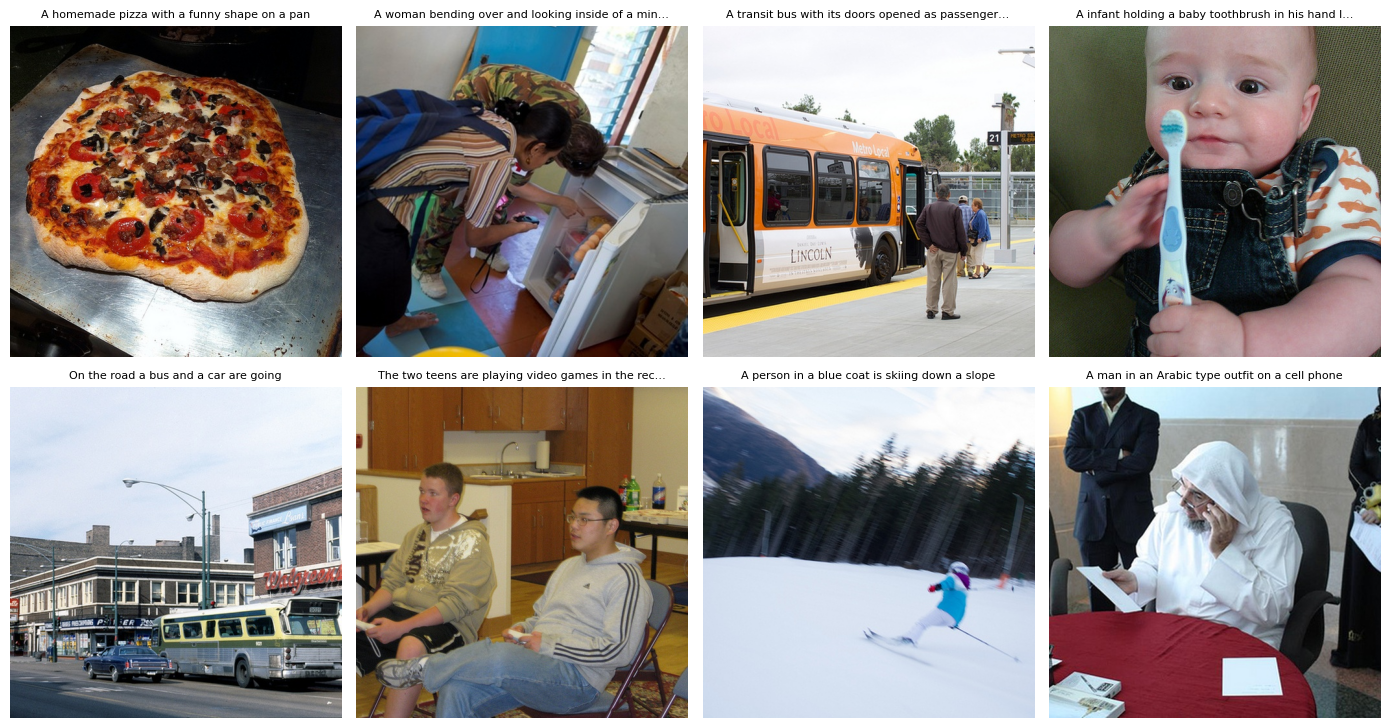

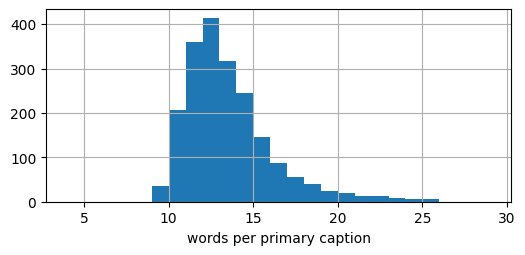

In [4]:
DATA = ROOT / "data" / "processed"
meta = load_metadata(DATA / "metadata.jsonl")
df = pd.DataFrame(meta)
df["n_words"] = df["caption"].str.split().str.len()

print(json.dumps(json.loads((DATA / "stats.json").read_text()), indent=2))

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, row in zip(axes.ravel(), df.sample(8, random_state=SEED).itertuples()):
    ax.imshow(Image.open(DATA / row.file)); ax.axis("off")
    ax.set_title(row.caption[:48] + ("…" if len(row.caption) > 48 else ""), fontsize=8)
plt.tight_layout(); plt.show()

df["n_words"].hist(bins=range(4, 30), figsize=(6, 2.5)); plt.xlabel("words per primary caption"); plt.show()

## 2. Text → embedding pipeline

SD v1.x conditions its UNet on the **last hidden states** of the CLIP ViT-L/14 text encoder: a tensor of shape `[77, 768]` per prompt. The **pooled** vector (hidden state at the EOS token) is a single 768-d sentence embedding, which we use for retrieval checks and later analysis.

In [5]:
tokenizer, text_encoder = load_text_encoder(device=DEVICE)

TEST_PROMPTS = json.loads((ROOT / "prompts" / "test_prompts.json").read_text())
prompts = [p["prompt"] for p in TEST_PROMPTS]

# Tokenisation: what the model actually sees
ids = tokenizer(prompts[0]).input_ids
print(len(ids), "tokens ->", tokenizer.convert_ids_to_tokens(ids))

enc = encode_text(prompts, tokenizer, text_encoder)
print("input_ids   :", tuple(enc["input_ids"].shape))
print("token_embeds:", tuple(enc["token_embeds"].shape), "<- UNet cross-attention input")
print("pooled      :", tuple(enc["pooled"].shape), "<- sentence-level vector")
print("truncated   :", enc["truncated"])

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[transformers] CLIPTextModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...23}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm1.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.

14 tokens -> ['<|startoftext|>', 'a</w>', 'red</w>', 'double</w>', '-</w>', 'decker</w>', 'bus</w>', 'driving</w>', 'down</w>', 'a</w>', 'rainy</w>', 'city</w>', 'street</w>', '<|endoftext|>']
input_ids   : (5, 77)
token_embeds: (5, 77, 768) <- UNet cross-attention input
pooled      : (5, 768) <- sentence-level vector
truncated   : [False, False, False, False, False]


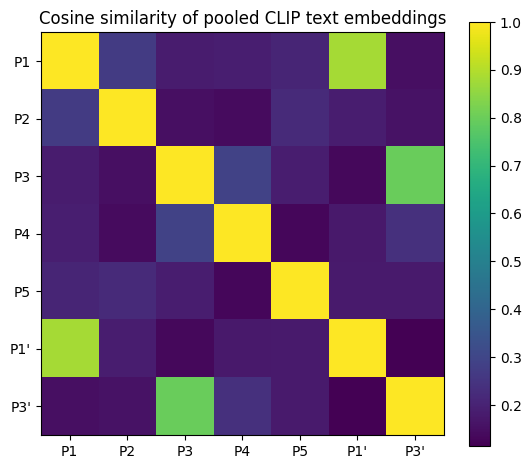

paraphrase P1~P1': 0.881 | unrelated P1~P2: 0.269


In [6]:
# Do semantically similar prompts land close together? (5 test prompts + 2 paraphrases)
probe = prompts + ["a double decker bus on a wet street in the rain", "a puppy leaping for a frisbee outdoors"]
emb = torch.nn.functional.normalize(encode_text(probe, tokenizer, text_encoder)["pooled"], dim=-1)
sim = (emb @ emb.T).numpy()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(sim, cmap="viridis"); plt.colorbar(im)
labels = [f"P{i+1}" for i in range(5)] + ["P1'", "P3'"]
ax.set_xticks(range(len(labels)), labels); ax.set_yticks(range(len(labels)), labels)
ax.set_title("Cosine similarity of pooled CLIP text embeddings"); plt.show()
print(f"paraphrase P1~P1': {sim[0, 5]:.3f} | unrelated P1~P2: {sim[0, 1]:.3f}")

## 3. Embed all captions + retrieval sanity check

Two goals: (a) cache caption embeddings for later experiments, and (b) verify the data cleaning didn't break image–caption alignment. If CLIP can retrieve the right validation image from its caption well above chance (1/N), the pairs are sound.

In [7]:
ART = ROOT / "artifacts"; ART.mkdir(exist_ok=True)
captions = df["caption"].tolist()
caption_emb = encode_corpus(captions, tokenizer, text_encoder)
torch.save({"image_id": df["image_id"].tolist(), "pooled": caption_emb}, ART / "caption_embeddings.pt")
print("saved", tuple(caption_emb.shape), "->", ART / "caption_embeddings.pt")

saved (1998, 768) -> /content/text2image-coco-diffusion/artifacts/caption_embeddings.pt


In [9]:
p = "src/t2i/evaluate.py"
s = open(p).read()
s = s.replace(
    "model.get_image_features(**inputs)",
    "model.visual_projection(model.vision_model(pixel_values=inputs['pixel_values']).pooler_output)",
)
s = s.replace(
    "model.get_text_features(**inputs)",
    "model.text_projection(model.text_model(input_ids=inputs['input_ids'], attention_mask=inputs.get('attention_mask')).pooler_output)",
)
open(p, "w").write(s)

import importlib, t2i.evaluate
importlib.reload(t2i.evaluate)
from t2i.evaluate import clip_scores, embed_images, embed_texts, load_clip, recall_at_k
print("patched")

patched


In [10]:
clip_model, clip_proc = load_clip(device=DEVICE)
val = df[df["split"] == "val"].reset_index(drop=True)
val_images = [Image.open(DATA / f).convert("RGB") for f in val["file"]]

img_emb = embed_images(val_images, clip_model, clip_proc)
txt_emb = embed_texts(val["caption"].tolist(), clip_model, clip_proc)
rec = recall_at_k(txt_emb, img_emb)
print(f"N_val={len(val)} | chance R@1 = {1/len(val):.4f}")
print({k: round(v, 3) for k, v in rec.items()})

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

N_val=199 | chance R@1 = 0.0050
{'R@1': 0.794, 'R@5': 0.975, 'R@10': 1.0}


## 4. Five prompt → image test runs (zero-shot SD v1.5)

Fixed seeds, 30 DPM-Solver++ steps, CFG 7.5, 512×512, so the later **LoRA fine-tuned** model can be compared on *identical* prompts and seeds.

In [11]:
del text_encoder; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free VRAM before loading SD

pipe = load_pipeline(device=DEVICE)
seeds = [p["seed"] for p in TEST_PROMPTS]
images = generate(pipe, prompts, seeds, steps=30, guidance=7.5)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

... (2 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

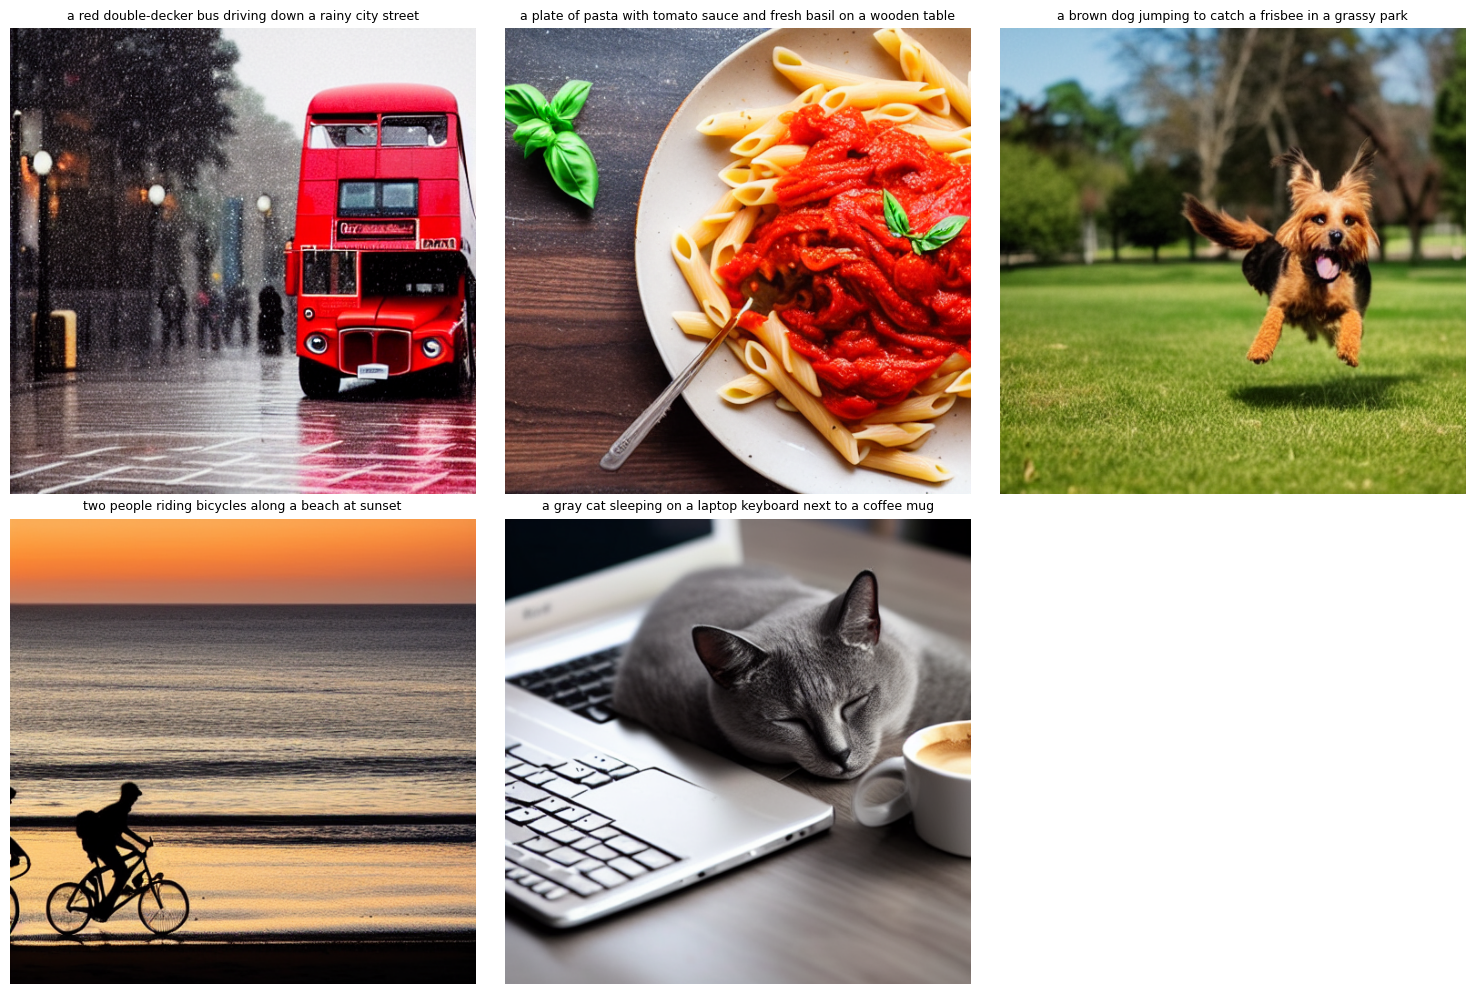

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, im, p in zip(axes.ravel(), images, prompts):
    ax.imshow(im); ax.axis("off"); ax.set_title(p, fontsize=9, wrap=True)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

## 5. Score and save

CLIPScore = 100 × cosine(image, prompt) under CLIP ViT-L/14 (higher = better prompt adherence). The absolute value depends on which CLIP model is used, so treat it as a **relative** baseline for comparing models on the same prompts and seeds, not as an absolute quality grade.

In [13]:
scores = clip_scores(images, prompts, clip_model, clip_proc)
results = pd.DataFrame({"prompt": prompts, "seed": seeds, "clip_score": np.round(scores, 2)})
display(results)
print("mean CLIPScore:", round(float(np.mean(scores)), 2))

config = dict(model=SD_MODEL_ID, scheduler="DPMSolverMultistep", steps=30, guidance=7.5,
              resolution=512, mean_clip_score=round(float(np.mean(scores)), 3))
save_run(ROOT / "results" / "baseline_v0", prompts, seeds, images, scores, config)
print("saved to", ROOT / "results" / "baseline_v0")

,prompt,seed,clip_score
0,a red double-decker bus driving down a rainy c...,42,30.58
1,a plate of pasta with tomato sauce and fresh b...,1234,25.74
2,a brown dog jumping to catch a frisbee in a gr...,7,25.14
3,two people riding bicycles along a beach at su...,2024,29.23
4,a gray cat sleeping on a laptop keyboard next ...,99,30.37


mean CLIPScore: 28.21
saved to /content/text2image-coco-diffusion/results/baseline_v0
